# Demo: describe a target image vs. two distractors

Placeholder images are generated by `make_images.py` (target: red circle, distractor1: blue circle, distractor2: red square).

In [1]:
from pathlib import Path

from PIL import Image

from reference_agent import build_graph, default_model, describe_target

# Settings (VLM_BASE_URL, VLM_MODEL, VLM_API_KEY) come from a .env file or the environment; see .env.example.
graph = build_graph(default_model())  # initialize the system

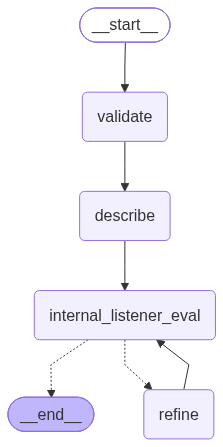

In [2]:
from IPython.display import Image as IPImage

# Rendered via the mermaid.ink web service (needs internet); print(graph.get_graph().draw_mermaid()) works offline.
display(IPImage(graph.get_graph().draw_mermaid_png()))

target


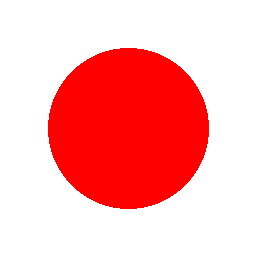

distractor1


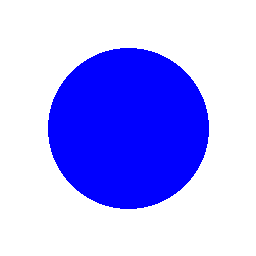

distractor2


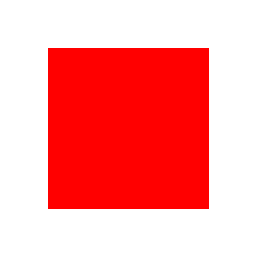

In [3]:
image_dir = Path("images")  # relative to this notebook
target = Image.open(image_dir / "target.png")
distractor1 = Image.open(image_dir / "distractor1.png")
distractor2 = Image.open(image_dir / "distractor2.png")

for name, img in [("target", target), ("distractor1", distractor1), ("distractor2", distractor2)]:
    print(name)
    display(img)

In [4]:
result = graph.invoke({"target": target, "distractor1": distractor1, "distractor2": distractor2})
print(result["description"])

The target is a solid red circle. It is red in color and circular in shape.


Step-by-step version: `stream_mode="updates"` yields one entry per executed node, with the state update that node returned. The loop `internal_listener_eval` -> `refine` -> `internal_listener_eval` ... becomes visible.

In [5]:
inputs = {"target": target, "distractor1": distractor1, "distractor2": distractor2}

for step, update in enumerate(graph.stream(inputs, stream_mode="updates"), start=1):
    for node, output in update.items():
        print(f"[{step}] node: {node}")
        for key, value in (output or {}).items():  # validate returns no state update
            print(f"      {key}: {value}")

[1] node: validate
[2] node: describe
      description: The target is a solid red circle. It is red in color and circular in shape.
[3] node: internal_listener_eval
      listener_choice: target
      attempts: 1


Shortcut with file paths (uses the default model):

In [6]:
print(describe_target(image_dir / "target.png", image_dir / "distractor1.png", image_dir / "distractor2.png"))

The target is a solid red circle. It is red in color and circular in shape.


Simple variant without the listener evaluation and refinement (one model call):

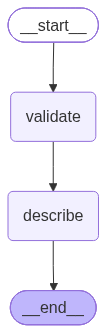

The target is a solid red circle. It is red in color and circular in shape.


In [7]:
simple_graph = build_graph(default_model(), use_listener=False)
display(IPImage(simple_graph.get_graph().draw_mermaid_png()))
print(simple_graph.invoke(inputs)["description"])